In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
#import scikitlearn as sk


In [55]:
sessions_df = pd.read_csv('../data/charging_sessions.csv')
weather_df = pd.read_csv('../data/weather_burbank_airport.csv')

sessions_df.head()


,Unnamed: 0,id,connectionTime,disconnectTime,doneChargingTime,kWhDelivered,sessionID,siteID,spaceID,stationID,timezone,userID,userInputs
0,0,5e23b149f9af8b5fe4b973cf,2020-01-02 13:08:54+00:00,2020-01-02 19:11:15+00:00,2020-01-02 17:31:35+00:00,25.016,1_1_179_810_2020-01-02 13:08:53.870034,1,AG-3F30,1-1-179-810,America/Los_Angeles,194.0,"[{'WhPerMile': 250, 'kWhRequested': 25.0, 'mil..."
1,1,5e23b149f9af8b5fe4b973d0,2020-01-02 13:36:50+00:00,2020-01-02 22:38:21+00:00,2020-01-02 20:18:05+00:00,33.097,1_1_193_825_2020-01-02 13:36:49.599853,1,AG-1F01,1-1-193-825,America/Los_Angeles,4275.0,"[{'WhPerMile': 280, 'kWhRequested': 70.0, 'mil..."
2,2,5e23b149f9af8b5fe4b973d1,2020-01-02 13:56:35+00:00,2020-01-03 00:39:22+00:00,2020-01-02 16:35:06+00:00,6.521,1_1_193_829_2020-01-02 13:56:35.214993,1,AG-1F03,1-1-193-829,America/Los_Angeles,344.0,"[{'WhPerMile': 400, 'kWhRequested': 8.0, 'mile..."
3,3,5e23b149f9af8b5fe4b973d2,2020-01-02 13:59:58+00:00,2020-01-02 16:38:39+00:00,2020-01-02 15:18:45+00:00,2.355,1_1_193_820_2020-01-02 13:59:58.309319,1,AG-1F04,1-1-193-820,America/Los_Angeles,1117.0,"[{'WhPerMile': 400, 'kWhRequested': 8.0, 'mile..."
4,4,5e23b149f9af8b5fe4b973d3,2020-01-02 14:00:01+00:00,2020-01-02 22:08:40+00:00,2020-01-02 18:17:30+00:00,13.375,1_1_193_819_2020-01-02 14:00:00.779967,1,AG-1F06,1-1-193-819,America/Los_Angeles,334.0,"[{'WhPerMile': 400, 'kWhRequested': 16.0, 'mil..."


In [56]:
weather_df.head()

,city,timestamp,temperature,cloud_cover,cloud_cover_description,pressure,windspeed,precipitation,felt_temperature
0,Burbank,2018-01-01 08:53:00,9.0,33.0,Fair,991.75,9.0,0.0,8.0
1,Burbank,2018-01-01 09:53:00,9.0,33.0,Fair,992.08,0.0,0.0,9.0
2,Burbank,2018-01-01 10:53:00,9.0,21.0,Haze,992.08,0.0,0.0,9.0
3,Burbank,2018-01-01 11:53:00,9.0,29.0,Partly Cloudy,992.08,0.0,0.0,9.0
4,Burbank,2018-01-01 12:53:00,8.0,33.0,Fair,992.08,0.0,0.0,8.0


In [57]:
sessions_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 66450 entries, 0 to 66449
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        66450 non-null  int64  
 1   id                66450 non-null  str    
 2   connectionTime    66450 non-null  str    
 3   disconnectTime    66450 non-null  str    
 4   doneChargingTime  62362 non-null  str    
 5   kWhDelivered      66450 non-null  float64
 6   sessionID         66450 non-null  str    
 7   siteID            66450 non-null  int64  
 8   spaceID           66450 non-null  str    
 9   stationID         66450 non-null  str    
 10  timezone          66450 non-null  str    
 11  userID            49187 non-null  float64
 12  userInputs        49187 non-null  str    
dtypes: float64(2), int64(2), str(9)
memory usage: 31.5 MB


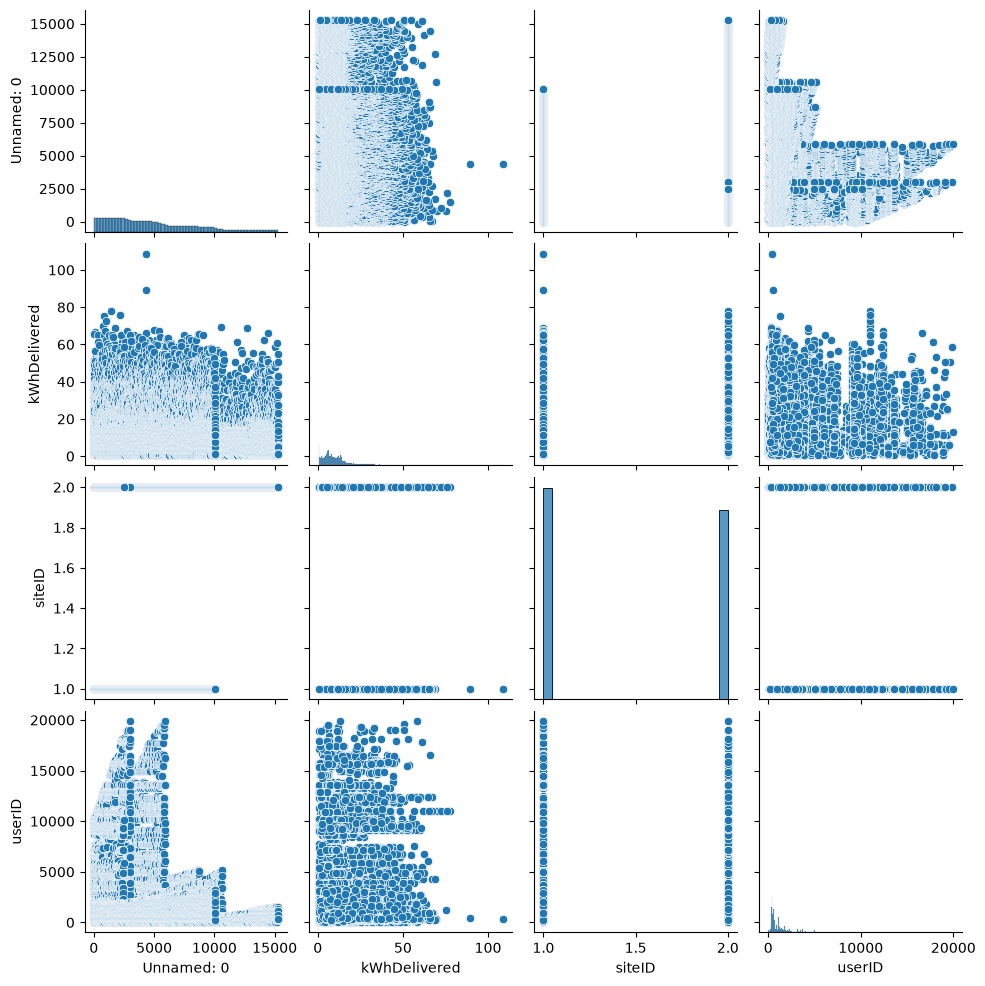

In [58]:
sns.pairplot(sessions_df)


In [59]:
sessions_df.describe()


,Unnamed: 0,kWhDelivered,siteID,userID
count,66450.000000,66450.000000,66450.000000,49187.000000
mean,4726.102062,11.787916,1.472656,1800.494582
std,3568.025394,10.314789,0.499256,2617.548614
min,0.000000,0.501000,1.000000,1.000000
25%,1845.000000,5.097000,1.000000,431.000000
50%,3960.000000,9.140000,1.000000,818.000000
75%,7027.000000,14.183000,2.000000,1805.000000
max,15291.000000,108.797242,2.000000,19923.000000


### Spaltenbeschreibungen


-spaceID: eindeutige Kennung eines Parkplatzes.



-stationID: eindeutige Kennung einer Ladestation (EVSE).



-siteID: eindeutige Kennung des Standorts.

In [60]:
sessions_df["siteID"].nunique()

2

In [61]:
sessions_df[sessions_df["siteID"]!=1].count()

Unnamed: 0          31408
id                  31408
connectionTime      31408
disconnectTime      31408
doneChargingTime    29358
kWhDelivered        31408
sessionID           31408
siteID              31408
spaceID             31408
stationID           31408
timezone            31408
userID              16372
userInputs          16372
dtype: int64

In [62]:
sessions_df[sessions_df["siteID"].isin([1,2]) == False].count()

Unnamed: 0          0
id                  0
connectionTime      0
disconnectTime      0
doneChargingTime    0
kWhDelivered        0
sessionID           0
siteID              0
spaceID             0
stationID           0
timezone            0
userID              0
userInputs          0
dtype: int64

In [63]:
sessions_df["stationID"].nunique()

107

In [64]:
sessions_df["spaceID"].nunique()

107

In [65]:
station_mapping = (
    sessions_df[
        ["siteID", "spaceID", "stationID"]
    ]
    .drop_duplicates()
    .sort_values(["siteID", "spaceID"])
)

station_mapping

,siteID,spaceID,stationID
1,1,AG-1F01,1-1-193-825
20,1,AG-1F02,1-1-193-827
2,1,AG-1F03,1-1-193-829
3,1,AG-1F04,1-1-193-820
15,1,AG-1F05,1-1-193-816
...,...,...,...
20556,2,CA-509,2-39-129-563
20200,2,CA-510,2-39-130-564
21348,2,CA-511,2-39-131-565
20179,2,CA-512,2-39-138-566


In [66]:
sessions_df.groupby("siteID").agg(
    sessions=("sessionID", "count"),
    stations=("stationID", "nunique"),
    parking_spaces=("spaceID", "nunique"),
    energy_kwh=("kWhDelivered", "sum")
)

,sessions,stations,parking_spaces,energy_kwh
siteID,,,,
1,35042,52,52,492801.112774
2,31408,55,55,290505.936292


# Standort Vermutung

## Standort 1 (siteID == 1)

AG: Arroyo Garage beim Jet Proulsion Lab 

Parkplatzschema: AG-1F01

Stationsschema: 1-1-193-825

Place: 	34.198841	-118.170402



## Standort 2 (siteID == 2)

CA: bei der Caltech

Parkplatzschema: CA-509

Stationsschema: 2-39-129-563

Place: 34.134765	-118.127183


|-- California_Garage_01/
    |   |-- California_Garage_02/
    |   |-- LIGO_01/
    |   |-- N_Wilson_Garage_01/
    |   `-- S_Wilson_Garage_01/

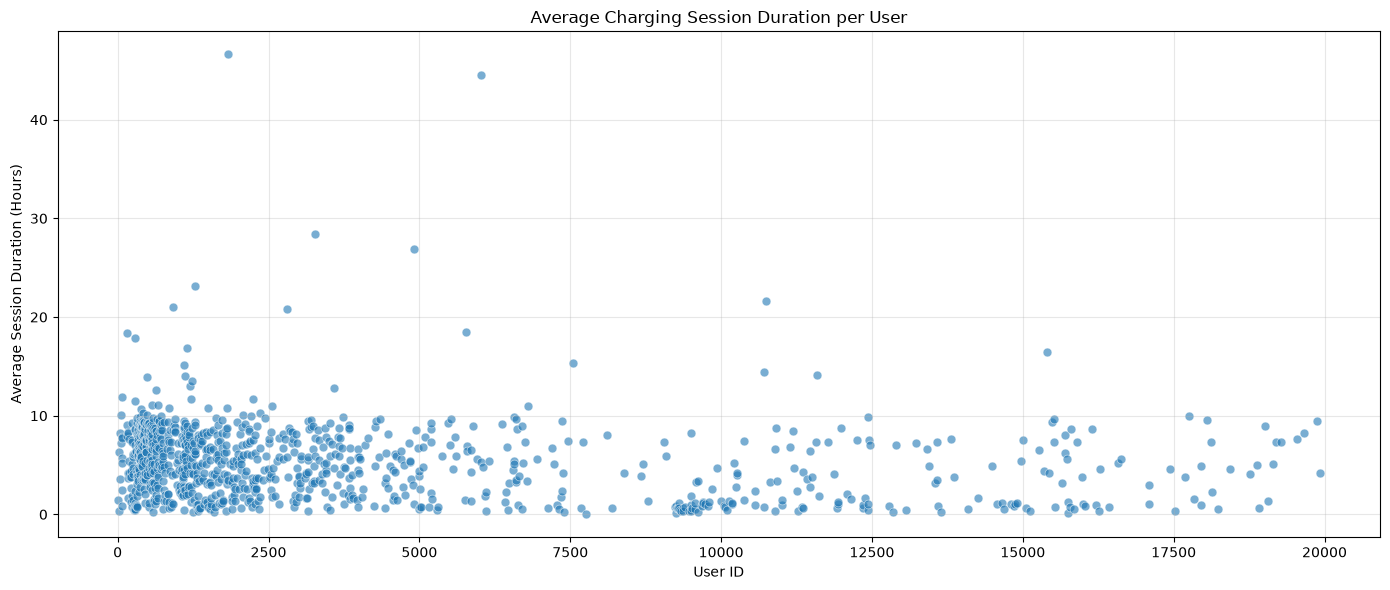

In [46]:
sessions_df["connectionTime"] = pd.to_datetime(
    sessions_df["connectionTime"]
)
sessions_df["disconnectTime"] = pd.to_datetime(
    sessions_df["disconnectTime"]
)

# Ladedauer in Stunden berechnen
sessions_df["duration_hours"] = (
    sessions_df["disconnectTime"] -
    sessions_df["connectionTime"]
).dt.total_seconds() / 3600

# Durchschnittliche Ausleihdauer je User berechnen
user_duration = sessions_df.groupby("userID")["duration_hours"].mean().reset_index()

# Scatterplot erstellen
plt.figure(figsize=(14, 6))

sns.scatterplot(
    data=user_duration,
    x="userID",
    y="duration_hours",
    alpha=0.6,
    s=40
)

plt.title("Average Charging Session Duration per User")
plt.xlabel("User ID")
plt.ylabel("Average Session Duration (Hours)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

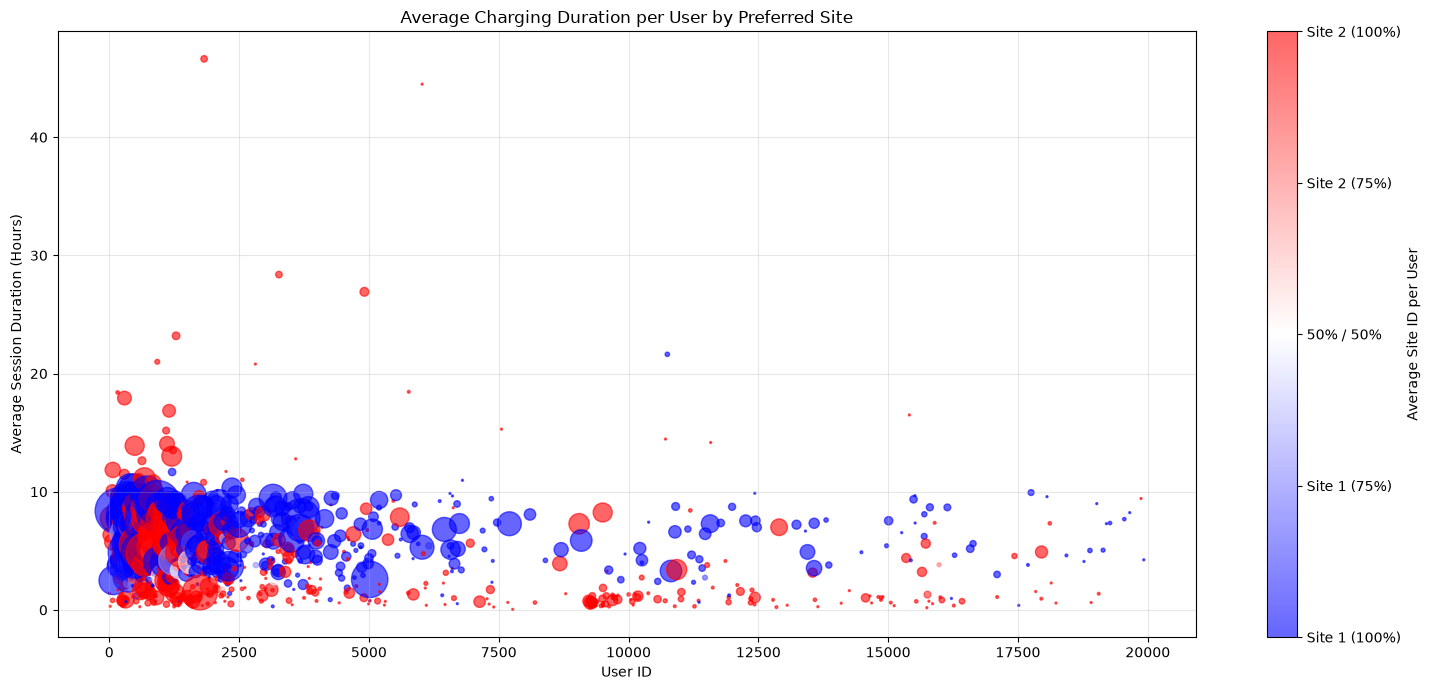

In [51]:
from matplotlib.colors import LinearSegmentedColormap


user_stats = (
    sessions_df
    .groupby("userID")
    .agg(
        avg_duration=("duration_hours", "mean"),
        avg_site=("siteID", "mean"),
        session_count=("sessionID", "count")
    )
    .reset_index()
)

# Eigene Farbskala erstellen
cmap = LinearSegmentedColormap.from_list(
    "site_gradient",
    ["blue", "white", "red"]
)

plt.figure(figsize=(15, 7))

scatter = plt.scatter(
    user_stats["userID"],
    user_stats["avg_duration"],
    c=user_stats["avg_site"],
    cmap=cmap,
    vmin=1,
    vmax=2,
    s=user_stats["session_count"] * 2,
    alpha=0.6
)


# Colorbar
cbar = plt.colorbar(scatter)
cbar.set_label("Average Site ID per User")
cbar.set_ticks([1, 1.25, 1.5, 1.75, 2])
cbar.set_ticklabels([
    "Site 1 (100%)",
    "Site 1 (75%)",
    "50% / 50%",
    "Site 2 (75%)",
    "Site 2 (100%)"
])

plt.title("Average Charging Duration per User by Preferred Site")
plt.xlabel("User ID")
plt.ylabel("Average Session Duration (Hours)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

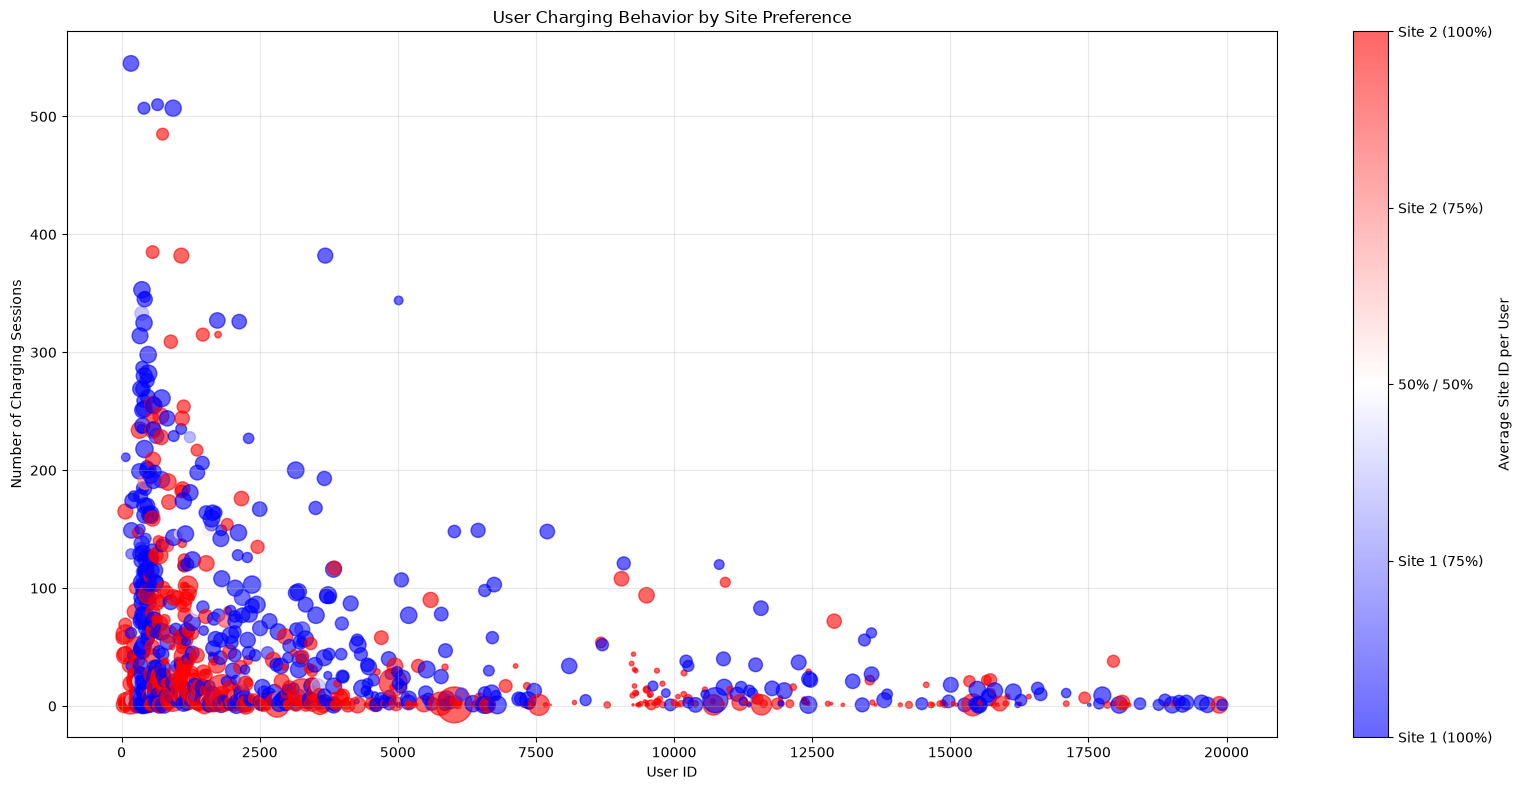

In [53]:
# Durchschnittliche Dauer, Standortpräferenz und Session-Anzahl je User
user_stats = (
    sessions_df
    .groupby("userID")
    .agg(
        avg_duration=("duration_hours", "mean"),
        avg_site=("siteID", "mean"),
        session_count=("sessionID", "count")
    )
    .reset_index()
)

# Farbskala: Blau = Site 1, Weiß = 50/50, Rot = Site 2
cmap = LinearSegmentedColormap.from_list(
    "site_gradient",
    ["blue", "white", "red"]
)

plt.figure(figsize=(16, 8))

scatter = plt.scatter(
    user_stats["userID"],
    user_stats["session_count"],
    c=user_stats["avg_site"],
    cmap=cmap,
    vmin=1,
    vmax=2,
    s=user_stats["avg_duration"] * 15,
    alpha=0.6
)

# Farbskala
cbar = plt.colorbar(scatter)
cbar.set_label("Average Site ID per User")
cbar.set_ticks([1, 1.25, 1.5, 1.75, 2])
cbar.set_ticklabels([
    "Site 1 (100%)",
    "Site 1 (75%)",
    "50% / 50%",
    "Site 2 (75%)",
    "Site 2 (100%)"
])

plt.title("User Charging Behavior by Site Preference")
plt.xlabel("User ID")
plt.ylabel("Number of Charging Sessions")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()